In [36]:
import cv2

image = cv2.imread("data/test1.png")

if image is None:
    raise FileNotFoundError("Image could not be loaded.")

In [37]:
print("Shape:", image.shape)
print("Size:", image.size)
print("Dtype:", image.dtype)
print("Itemsize:", image.itemsize)
print("Nbytes:", image.nbytes)

Shape: (1086, 1448, 3)
Size: 4717584
Dtype: uint8
Itemsize: 1
Nbytes: 4717584


In [38]:
image_16 = image.astype("uint16")

In [39]:
print("Shape:", image_16.shape)
print("Size:", image_16.size)
print("Dtype:", image_16.dtype)
print("Itemsize:", image_16.itemsize)
print("Nbytes:", image_16.nbytes)

Shape: (1086, 1448, 3)
Size: 4717584
Dtype: uint16
Itemsize: 2
Nbytes: 9435168


In [40]:
image_16 = image.astype("uint16")

print("Original:", image.dtype, image.nbytes)
print("Converted:", image_16.dtype, image_16.nbytes)

print("Same pixel values:", (image == image_16).all())

Original: uint8 4717584
Converted: uint16 9435168
Same pixel values: True


In [41]:
x = 100
y = 200

pixel = image[y, x]
print("Pixel BGR:", pixel)

Pixel BGR: [81 88 82]


In [42]:
modified_image = image.copy()

# Complete the slicing yourself
modified_image[100:200, 200:300] = [0, 0, 255]

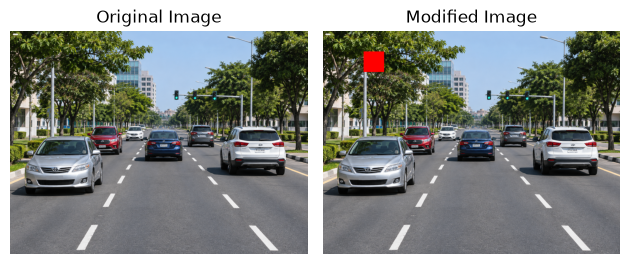

In [43]:
import matplotlib.pyplot as plt

# Original image
plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")

# Modified image
plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(modified_image, cv2.COLOR_BGR2RGB))
plt.title("Modified Image")
plt.axis("off")

plt.tight_layout()
plt.show()

In [44]:
blue_channel = image[:, :, 0]
green_channel = image[:, :, 1]
red_channel = image[:, :, 2]

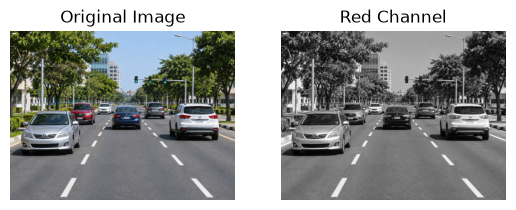

In [45]:
# Original image
plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(red_channel, cmap="gray")
plt.title("Red Channel")
plt.axis("off")
plt.show()

In [46]:
rgb_image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

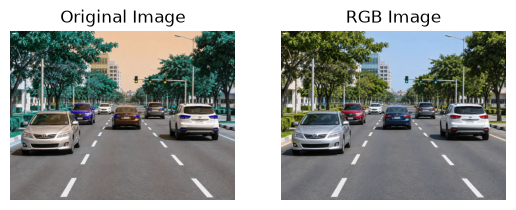

In [47]:
# Original image
plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(rgb_image, cmap="gray")
plt.title("RGB Image")
plt.axis("off")
plt.show()

In [48]:
import numpy as np

# OpenCV grayscale conversion
gray_cv = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

# Extract BGR channels
blue = image[:, :, 0]
green = image[:, :, 1]
red = image[:, :, 2]

# Manual grayscale conversion
gray_float = (
    0.114 * blue
    + 0.587 * green
    + 0.299 * red
)

# Round and convert to uint8
gray_manual = np.round(gray_float).astype("uint8")

# Compare results
difference = cv2.absdiff(gray_cv, gray_manual)

print("OpenCV shape:", gray_cv.shape)
print("Manual shape:", gray_manual.shape)
print("OpenCV dtype:", gray_cv.dtype)
print("Manual dtype:", gray_manual.dtype)
print("Maximum difference:", difference.max())
print("Mean absolute difference:", difference.mean())
print("Identical pixels:", np.count_nonzero(difference == 0))
print("Total pixels:", difference.size)

OpenCV shape: (1086, 1448)
Manual shape: (1086, 1448)
OpenCV dtype: uint8
Manual dtype: uint8
Maximum difference: 1
Mean absolute difference: 0.00019649888587039467
Identical pixels: 1572219
Total pixels: 1572528


In [49]:
hsv_image = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)

print("BGR Shape:", image.shape)
print("HSV Shape:", hsv_image.shape)
print("HSV Dtype:", hsv_image.dtype)

BGR Shape: (1086, 1448, 3)
HSV Shape: (1086, 1448, 3)
HSV Dtype: uint8


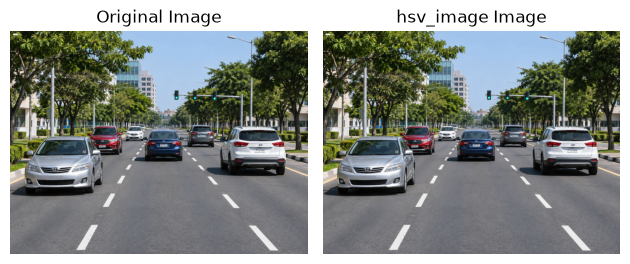

In [50]:
# Original image
plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")

# Modified image
plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(hsv_image, cv2.COLOR_HSV2RGB))
plt.title("hsv_image Image")
plt.axis("off")

plt.tight_layout()
plt.show()

In [51]:
hue_channel = hsv_image[:, :, 0]
saturation_channel = hsv_image[:, :, 1]
value_channel = hsv_image[:, :, 2]

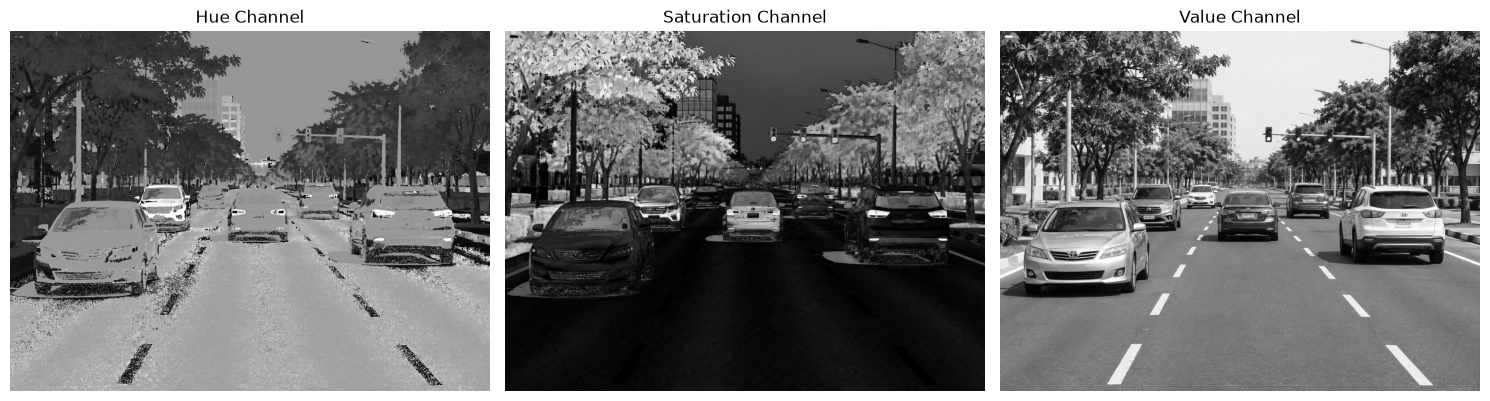

In [52]:
# Plot HSV channels
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(hue_channel, cmap="gray", vmin=0, vmax=179)
plt.title("Hue Channel")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(saturation_channel, cmap="gray", vmin=0, vmax=255)
plt.title("Saturation Channel")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(value_channel, cmap="gray", vmin=0, vmax=255)
plt.title("Value Channel")
plt.axis("off")

plt.tight_layout()
plt.show()

In [53]:
lower_red = np.array([0, 100, 70])
upper_red = np.array([10, 255, 255])

red_mask = cv2.inRange(hsv_image, lower_red, upper_red)

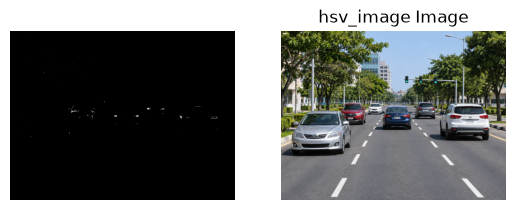

In [54]:
plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(hsv_image, cv2.COLOR_HSV2RGB))
plt.title("hsv_image Image")
plt.axis("off")

plt.subplot(1, 2, 1)
plt.imshow(red_mask, cmap="gray", vmin=0, vmax=255)
plt.axis("off")
plt.show()

In [55]:
lower_red_150 = np.array([0, 150, 70])

red_mask_150 = cv2.inRange(
    hsv_image,
    lower_red_150,
    upper_red
)

print("S >= 100:", cv2.countNonZero(red_mask))
print("S >= 150:", cv2.countNonZero(red_mask_150))

S >= 100: 1299
S >= 150: 938


In [56]:
lower_red_2 = np.array([170, 100, 70])
upper_red_2 = np.array([179, 255, 255])

red_mask_2 = cv2.inRange(
    hsv_image,
    lower_red_2,
    upper_red_2
)

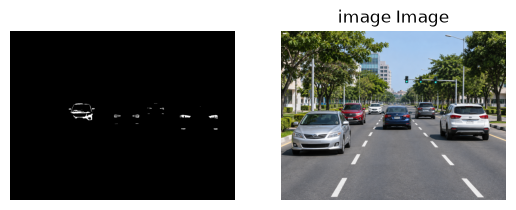

In [57]:
plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title("image Image")
plt.axis("off")

plt.subplot(1, 2, 1)
plt.imshow(red_mask_2, cmap="gray", vmin=0, vmax=255)
plt.axis("off")
plt.show()

In [58]:
red_mask_combined = cv2.bitwise_or(red_mask, red_mask_2)

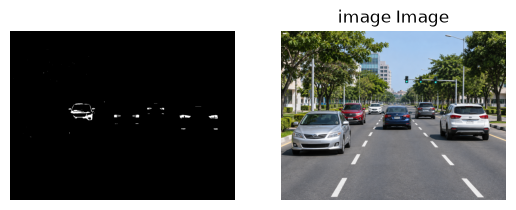

In [59]:
plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title("image Image")
plt.axis("off")

plt.subplot(1, 2, 1)
plt.imshow(red_mask_combined, cmap="gray", vmin=0, vmax=255)
plt.axis("off")
plt.show()

In [60]:
red_result = cv2.bitwise_and(
    image,
    image,
    mask=red_mask_combined
)  #RGB

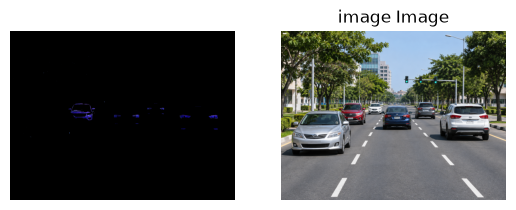

In [61]:
plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title("image Image")
plt.axis("off")

plt.subplot(1, 2, 1)
plt.imshow(red_result, cmap="gray", vmin=0, vmax=255)
plt.axis("off")
plt.show()

In [62]:

pixels = np.array([-20, 30, 100, 255, 320])

np.clip(pixels, 0, 255, out=pixels)

array([  0,  30, 100, 255, 255])

In [65]:
def adjust_brightness_contrast(
    image: np.ndarray,
    alpha: float = 1.0,
    beta: float = 0.0
) -> np.ndarray:
    """
    Adjust the brightness and contrast of a uint8 image.

    Parameters:
        image (np.ndarray): Input uint8 image.
        alpha (float): Contrast scaling factor.
        beta (float): Brightness offset.

    Returns:
        np.ndarray: Adjusted uint8 image.
    """
    adjusted = image.astype(np.float32) * alpha + beta

    np.clip(adjusted, 0, 255, out=adjusted)

    return np.rint(adjusted).astype(np.uint8)

In [66]:
experiments = [
    ("Original", 1.0, 0),
    ("Increase Brightness", 1.0, 50),
    ("Decrease Brightness", 1.0, -50),
    ("Increase Contrast", 1.5, 0),
    ("Decrease Contrast", 0.5, 0),
    ("Contrast + Brightness", 1.5, -50),
]

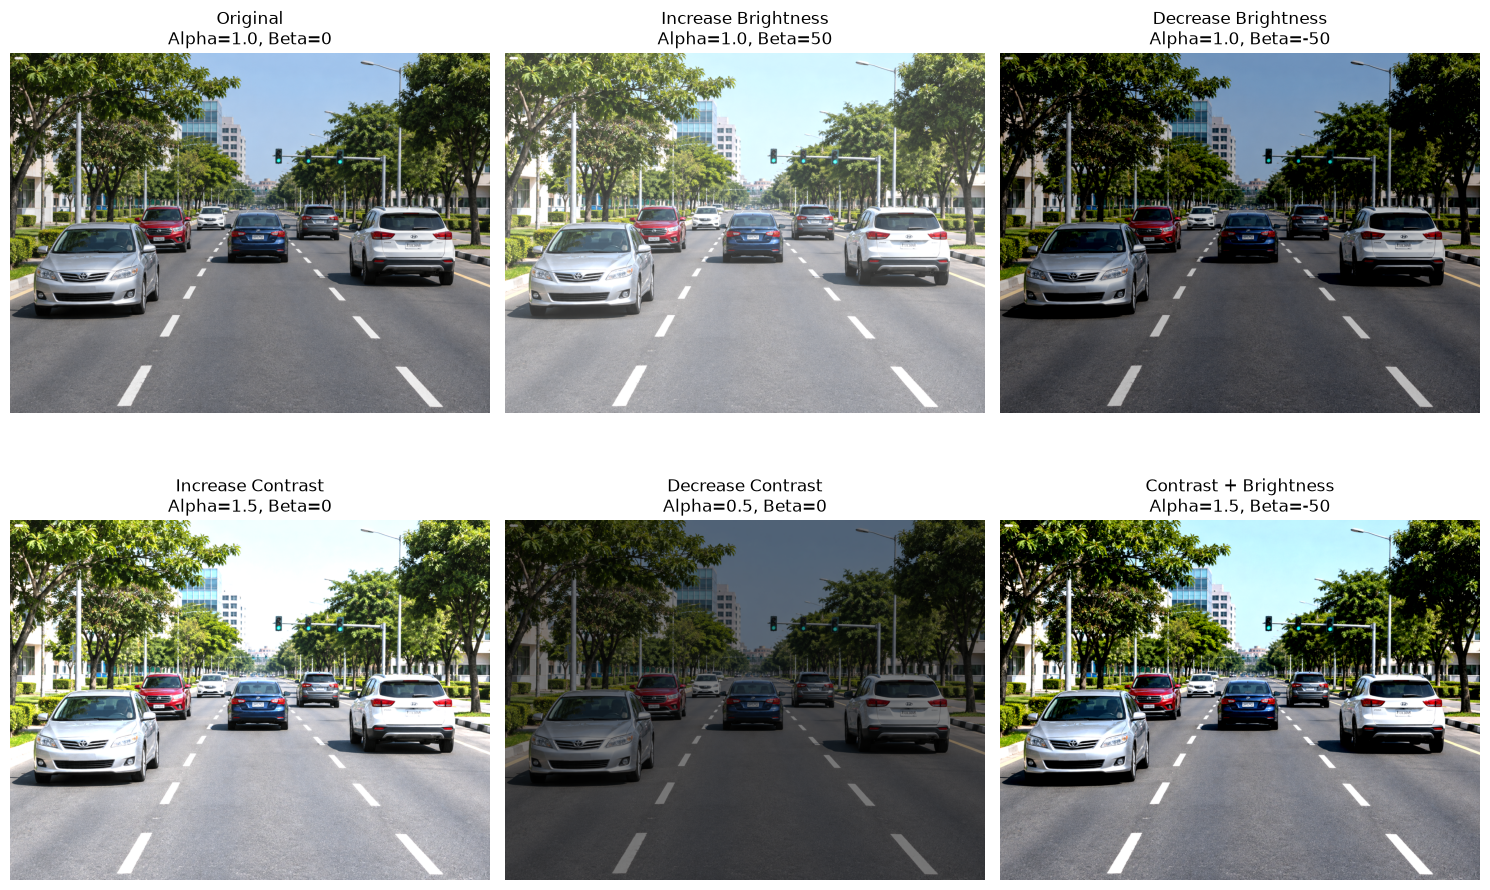

In [68]:
fig, axes = plt.subplots(2, 3, figsize=(15, 10))

for ax, (title, alpha, beta) in zip(
    axes.ravel(), experiments
):
    adjusted = adjust_brightness_contrast(
        cv2.cvtColor(image, cv2.COLOR_BGR2RGB),
        alpha=alpha,
        beta=beta
    )

    ax.imshow(adjusted)
    ax.set_title(f"{title}\nAlpha={alpha}, Beta={beta}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [69]:
pixels = np.array([0, 50, 100, 200, 255], dtype=np.uint8)

result = adjust_brightness_contrast(
    pixels,
    alpha=1.5,
    beta=20
)

expected = np.array([20, 95, 170, 255, 255], dtype=np.uint8)

assert np.array_equal(result, expected)
assert result.dtype == np.uint8

# Verify identity transformation
assert np.array_equal(
    adjust_brightness_contrast(image),
    image
)

print("All tests passed!")

All tests passed!
